# Reproducible runs

A number from this package can be traced back to the exact configuration that made it.
Four mechanisms do that, and this notebook shows each one:

1. **A run configuration file** (TOML) that *selects* documented behaviour and never
   *describes* a threshold.
2. **Named profiles**: every threshold that differs between UIOOPS releases or campaigns
   lives in a registered, cited profile.
3. **An author-defaults file** for the one case where a team sets its own reject
   thresholds. Each value carries a citation, and the file name carries a hash of its
   content.
4. **`.call` stamps** beside every output. A later stage refuses an input whose stamp
   disagrees with its own configuration.

**Before this:** [10_labelling_particles](10_labelling_particles.ipynb). **Next:** [03_whole_campaign](03_whole_campaign.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/2_processing/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

from arrayprobe.config import ConfigError, load_config

cfg_path = Path("tests/data/demo_flight_v35_run.toml")
print(cfg_path.read_text(encoding="utf-8"))
cfg = load_config(cfg_path)
print("profile selected:", cfg.profile.name)

# The v3.5 demo-flight reference's run configuration (built by scripts/make_demo_reference.py).
# stock-v3.5 is the configuration a new user should run: nothing here is ORACLES-specific.
# Paths are relative to this file. `arrayprobe run demo_flight_v35_run.toml <raw.2DS>`.
[fidelity]
profile = "stock-v3.5"

[run]
engine = "3.5"
preset = "DEMO_2DS_H"
out = "_decoded"
stages = "234c"
tas_file = "demo_flight_v35_aircraft.cdf"

[combine]
borrowed = true

profile selected: stock-v3.5


## 1. A configuration selects; it never sets a threshold

A key that would set a threshold directly is refused with a message naming what the file
may say instead. A config therefore cannot quietly change a computed number: anything that
does is named in the file as a profile.

In [2]:
import tempfile

tmp = tempfile.TemporaryDirectory()
root = Path(tmp.name)
bad = root / "bad_run.toml"
bad.write_text('[fidelity]\nprofile = "stock-v3.5"\nmax_edge_img_ar = 4.0\n\n'
               '[run]\nengine = "3.5"\n', encoding="utf-8")
try:
    load_config(bad)
except ConfigError as err:
    print("refused:", str(err).split(" (one of")[0])

refused: [fidelity] sets ['max_edge_img_ar']: fidelity thresholds are chosen by [fidelity].profile


## 2. Profiles are named and cited

The shipped profiles, and the reject thresholds on which they differ.

The profile the v3.5 engine runs under by default, and its reject thresholds:

In [4]:
from arrayprobe import profiles

p = profiles.STOCK_V35
r = p.reject_thresholds
print(f"{p.name:20s} rej_hollow={r.rej_hollow!s:5s} max_edge_img_ar={r.max_edge_img_ar:<4g} "
      f"max_comp_img_ar={r.max_comp_img_ar:g}")


stock-v3.5           rej_hollow=True  max_edge_img_ar=6    max_comp_img_ar=5


`ORACLES_PRODUCTION` differs from stock because that campaign's processing tree carried
dated edits to three reject thresholds; the profile's fields cite the lines. A team with
its own processing tree registers its own profile from Python (`register_profile`), so
the values sit in reviewed code rather than in a run file.

## 3. An author-defaults file

The one file that may carry threshold values: a base profile plus overrides of the six
reject thresholds, each with a citation. Its name must be `authordefaults-<hash>.toml`,
where the hash is taken over the file's own bytes. An edit without a rename is refused, so
the name in a stamp always identifies the values that ran.

In [5]:
from arrayprobe.authordefaults import (
    AuthorDefaultsError,
    expected_filename,
    load_authordefaults,
    resolve_profile,
)

body = (b'[fidelity]\nbase_profile = "STOCK_V35"\n\n'
        b'[thresholds.max_edge_img_ar]\nvalue = 4.5\n'
        b'citation = "Example team, 2026 field campaign: edge-touching aspect ratio review"\n')
ad_path = root / expected_filename(body)
ad_path.write_bytes(body)
ad = load_authordefaults(ad_path)
prof = resolve_profile(ad)
print("file:", ad_path.name)
print("base:", ad.base_profile_name, "| overrides:", ad.overrides)
print("generated profile:", prof.name,
      "| max_edge_img_ar =", prof.reject_thresholds.max_edge_img_ar)

ad_path.write_bytes(body.replace(b"4.5", b"5.0"))   # edited, not renamed
try:
    load_authordefaults(ad_path)
except AuthorDefaultsError as err:
    print(f"\nrefused after an edit: {str(err)[:200]} ...")

file: authordefaults-3f07ca4447c844c4.toml
base: stock-v3.5 | overrides: {'max_edge_img_ar': 4.5}
generated profile: authordefaults-3f07ca4447c844c4 | max_edge_img_ar = 4.5

refused after an edit: authordefaults-3f07ca4447c844c4.toml does not match its own content: expected 'authordefaults-095387391f4d5d89.toml'. Rename the file (or regenerate it) after any edit -- the mismatch is the whole poi ...


## 4. Stamps, and a stage that refuses a mismatched input

The cell decodes and frames the dense synthetic 2D-S flight on the v3.5 engine, then asks
the size-distribution stage for the same file under a *different* profile. The stage reads
the framing stage's stamp, sees that it disagrees and refuses: a product made one way never
silently continues under another. (`--accept-unstamped` exists for inputs made before
stamps did; it is not a way round a disagreement.)

In [6]:
import shutil
import sys

import netCDF4
import numpy as np

from arrayprobe import profiles

sys.path.insert(0, "scripts")
import run_flight  # noqa: E402

run_flight.log = lambda *a, **kw: None
run_flight.use_preset("DEMO_2DS_H")
run_flight.ENGINE, run_flight.PROFILE = "3.5", profiles.STOCK_V35
out = root / "run"
out.mkdir()
raw = out / "base160101000000.2DS"
shutil.copyfile("tests/data/demo_flight_dense_raw.2DS", raw)
secs = 6 * 3600 + 6 * 60 + 20 + np.arange(50)
with netCDF4.Dataset(str(out / "aircraft.cdf"), "w", format="NETCDF3_CLASSIC") as ds:
    ds.createDimension("time", secs.size)
    ds.createVariable("Time", "f8", ("time",))[:] = (
        (secs // 3600) * 10000 + (secs % 3600 // 60) * 100 + secs % 60).astype(float)
    ds.createVariable("TAS", "f8", ("time",))[:] = 130.0
run_flight.TAS_FILE = str(out / "aircraft.cdf")

image = run_flight.stage2(raw, out)
proc = run_flight.stage3(image, out)
print("framing stamp:", Path(f"{proc}.call").read_text(encoding="utf-8").strip()[:150], "...")

run_flight.PROFILE = prof           # the author-defaults profile from section 3
try:
    run_flight.stage4(proc, raw.stem, out)
except run_flight.UnverifiableProvenance as err:
    print(f"\nsize-distribution stage refused:\n{err}")

framing stamp: engine=3.5 profile=stock-v3.5 reject=(rej_zero_area=True,rej_split=True,rej_hollow=True,shadowed_area=25,max_edge_img_ar=6,max_comp_img_ar=5) shadow_d ...

size-distribution stage refused:
proc.base160101000000.H.nc was built with engine=3.5 profile=stock-v3.5 reject=(rej_zero_area=True,rej_split=True,rej_hollow=True,shadowed_area=25,max_edge_img_ar=6,max_comp_img_ar=5) shadow_diode=none tas_file=aircraft.cdf call=(iRectEllipse=0,iCalcAllDiodeStats=0,iQC=0,iNewHabit=0,tas_ratio=off) software=UIOOPS_v3.5 stray_pixel=off, but this run wants engine=3.5 profile=authordefaults-3f07ca4447c844c4 reject=(rej_zero_area=True,rej_split=True,rej_hollow=True,shadowed_area=25,max_edge_img_ar=4.5,max_comp_img_ar=5) shadow_diode=none tas_file=aircraft.cdf call=(iRectEllipse=0,iCalcAllDiodeStats=0,iQC=0,iNewHabit=0,tas_ratio=off) software=UIOOPS_v3.5 stray_pixel=off; run S3 for it again rather than building an sd file on top of it


The same data in xarray, which most earth-science tools read:

<xarray.Dataset> Size: 46kB
Dimensions:                         (time: 240, pos_count: 2, bin_count: 128)
Dimensions without coordinates: time, pos_count, bin_count
Data variables: (12/40)
    Date                            (time) int32 960B 20160906 ... 20160906
    Time                            (time) int32 960B 60640 60640 ... 60659
    msec                            (time) int16 480B 250 250 250 ... 250 250
    Time_in_seconds                 (time) float64 2kB 20.65 20.65 ... 20.7 20.7
    SliceCount                      (time) int16 480B 14 9 16 16 ... 40 16 16 26
    DMT_DOF_SPEC_OVERLOAD           (time) float64 2kB 0.0 0.0 0.0 ... 0.0 0.0
    ...                              ...
    holroyd_habit                   (time) int16 480B 115 115 115 ... 115 115
    fine_detail_ratio               (time) float64 2kB 4.182 10.0 ... 4.449
    sphericity                      (time) float64 2kB 0.3266 0.3099 ... 0.2707
    area_hole_ratio                 (time) float64 2kB 0.0 0.0 ..

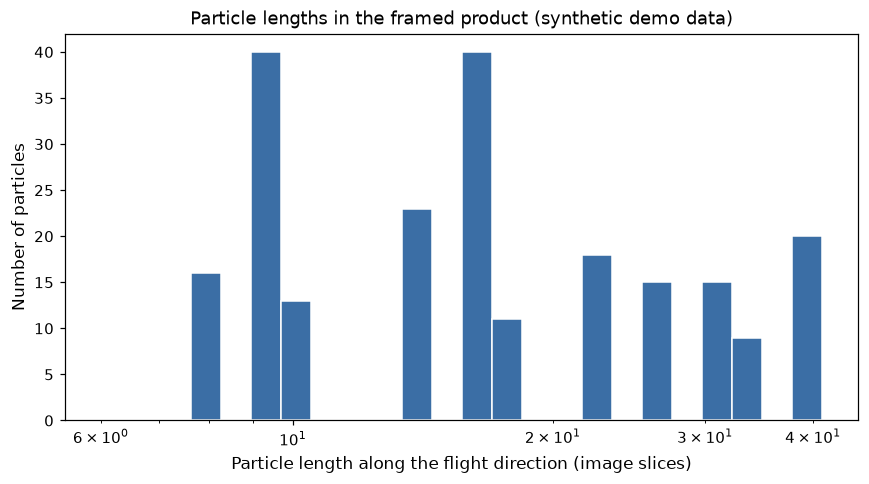

In [7]:
import re


def without_local_paths(data):
    """A copy whose path-valued global attributes keep only the file name.

    The file records the absolute path of the input the demo run read; showing it
    would print a folder on this machine. The file on disk is unchanged."""
    shown = data.copy()
    shown.attrs = {k: re.split(r"[/\\]", v)[-1] if isinstance(v, str) and re.match(r"(~|[A-Za-z]:|/)", v) else v
                   for k, v in data.attrs.items()}
    return shown


import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

with xr.open_dataset(proc) as ds:
    ds = ds.load()
print(without_local_paths(ds))

# image_length: the particle's extent along the flight direction, in image slices.
length = ds["image_length"].values
length = length[length > 0]
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.logspace(np.log10(length.min()), np.log10(length.max() + 1), 25)
ax.hist(length, bins=bins, color="#3b6ea5", edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("Particle length along the flight direction (image slices)", fontsize=11)
ax.set_ylabel("Number of particles", fontsize=11)
ax.tick_params(labelsize=10)
ax.set_title("Particle lengths in the framed product (synthetic demo data)", fontsize=12)
fig.tight_layout()
plt.show()

*Figure 1. How long the particles in the framed product are, read with xarray from the same file the stamp describes. They run from about 5 to 40 slices.*

## What to keep with a result

- the run configuration file, and the author-defaults file if it names one;
- the `.call` stamps beside every product: engine, profile, preset and airspeed source,
  in one line per stage;
- the package version (`arrayprobe --version`).

With those three, the same raw file gives the same bytes: the port's reproductions are
byte-compared against the archived products and the Octave oracle, not approximated.

---

## Re-running a product from its own stamp

Every product the run driver writes has a `.call` sidecar stating the engine and configuration
that made it. `arrayprobe reprocess` reads that stamp, re-runs the stage that wrote the product
under exactly that configuration, and reports whether the fresh output is identical. This notebook
processes the package's small demo flight with the v3.5 engine, shows the size-distribution
product's stamp, re-runs it and finds no difference, changes one stored value in a copy and shows
the difference reported, and shows the products that cannot be re-run from a stamp. It runs in
seconds on the tracked demo data.

## Process the demo flight

The tracked demo raw file and its aircraft file are copied to a temporary directory and run
through stages 2 to 4 (decode, image processing, size distribution) with the v3.5 engine, from a
TOML run configuration, by the same `arrayprobe run` command a user types.

In [8]:
import os
import shutil
import subprocess
import sys
import tempfile

DATA = Path("tests/data")
work = Path(tempfile.mkdtemp(prefix="nb42_"))
raw = work / "base160101000000.2DS"
shutil.copyfile(DATA / "demo_flight_v314_raw.2DS", raw)
shutil.copyfile(DATA / "demo_flight_v35_aircraft.cdf", work / "demo_flight_v35_aircraft.cdf")
toml = work / "run.toml"
toml.write_text(
    "[fidelity]\n"
    'profile = "stock-v3.5"\n\n'
    "[run]\n"
    'engine = "3.5"\n'
    'preset = "DEMO_2DS_H"\n'
    'out = "_decoded"\n'
    'stages = "234"\n'
    'tas_file = "demo_flight_v35_aircraft.cdf"\n',
    encoding="utf-8",
)
env = dict(os.environ, PYTHONPATH=os.pathsep.join(
    [str(Path("src").resolve()), *filter(None, [os.environ.get("PYTHONPATH")])]))
done = subprocess.run([sys.executable, "-m", "arrayprobe.cli", "run", str(toml), str(raw)],
                      capture_output=True, text=True, encoding="utf-8", errors="replace",
                      timeout=600, env=env)
assert done.returncode == 0, done.stderr[-2000:]
out = work / "_decoded"
for p in sorted(out.iterdir()):
    print(p.name)

_inflight
base160101000000.H.nc
base160101000000.H.nc.call
base160101000000.H.nc.decode
base160101000000.load.json
base160101000000.NV.csv
base160101000000.tas.csv
proc.base160101000000.H.nc
proc.base160101000000.H.nc.call
sd.base160101000000.H.nc
sd.base160101000000.H.nc.call
sd.base160101000000.H.nc.tasqc.json


## The stamp

The size-distribution product `sd.<stem>.H.nc` has its stamp in `sd.<stem>.H.nc.call`: the
engine, the profile, the reject thresholds, the diode mask, the aircraft file's name and the
switches the run used.

In [9]:
sd = next(p for p in out.iterdir() if p.name.startswith("sd.") and p.suffix == ".nc")
stamp = Path(str(sd) + ".call").read_text().strip()
print(sd.name)
for part in stamp.split(" "):
    print(" ", part)
assert stamp.startswith("engine=3.5 ") and "profile=stock-v3.5" in stamp

sd.base160101000000.H.nc
  engine=3.5
  iat_file=<none>
  profile=stock-v3.5
  reject=(rej_zero_area=True,rej_split=True,rej_hollow=True,shadowed_area=25,max_edge_img_ar=6,max_comp_img_ar=5)
  shadow_diode=none
  tas_file=demo_flight_v35_aircraft.cdf
  call=(iRectEllipse=0,iCalcAllDiodeStats=0,iQC=0,iNewHabit=0,tas_ratio=off)
  software=UIOOPS_v3.5
  stray_pixel=on:g8,n2,m9
  sizedist=(iaThreshType=0,iCreateAspectRatio=0,iCreateBad=0,iSaveIntArrSV=0)
  bins=2ds-ladder(V11-fix)
  time_sv_fix=on
  zero_sv_seconds=0
  time_grid_fix=0
  time_grid_unresolved=0
  plausibility=(sec=4,pos=1.0000,nonfinite=0,dup=0,bins=128,accepted=5,ok)


## Re-run from the stamp: identical

`reprocess` is given only the product and the campaign preset, which no stamp records. It accepts
the configuration the stamp proposes only if the driver, run under it, would write the same stamp
character for character, re-runs the size-distribution stage in a temporary directory and
compares every dimension, variable, stored value and attribute. The creation time is skipped and
source paths are compared by file name.

In [10]:
from arrayprobe.driver import reprocess as rp

result = rp.reprocess(sd, preset="DEMO_2DS_H")
print("stage:", result.stage, "| engine:", result.engine)
print("differences:", result.differences)
assert (result.stage, result.engine) == ("S4", "3.5")
assert result.identical and result.differences == []

stage: S4 | engine: 3.5
differences: []


The command line gives the same answer, with exit status 0 for identical, 1 for a difference
and 2 for a refusal.

In [11]:
cmd = [sys.executable, "-m", "arrayprobe.cli", "reprocess", str(sd), "--preset", "DEMO_2DS_H"]
done = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace",
                      timeout=600, env=env)
print("exit status:", done.returncode)
print(next(line for line in done.stdout.splitlines() if line.startswith("result")))
assert done.returncode == 0 and "IDENTICAL" in done.stdout

exit status: 0
result  : IDENTICAL (every dimension, variable and attribute; Creation Time skipped, source paths compared by basename)


## Change one value: the difference is reported

A copy of the flight's directory has one stored value of the product changed by one unit, with its
stamp left as it was. Re-running from the stamp reports that variable and how many elements
differ.

In [12]:
import netCDF4
import numpy as np

edited = work / "edited"
shutil.copytree(out, edited)
sd_edited = edited / sd.name
with netCDF4.Dataset(str(sd_edited), "a") as ds:
    name = next(n for n, v in ds.variables.items()
                if v.ndim >= 1 and v.size > 0 and v.dtype.kind == "f")
    var = ds.variables[name]
    var.set_auto_maskandscale(False)
    first = (slice(0, 1),) * var.ndim
    var[first] = np.asarray(var[first]) + 1
print("changed the first element of", name)

changed = rp.reprocess(sd_edited, preset="DEMO_2DS_H")
for line in changed.differences:
    print(line)
assert not changed.identical
assert changed.differences == [f"/{name}: stored values differ (1 element(s))"]

changed the first element of time
/time: stored values differ (1 element(s))


## What cannot be re-run from a stamp

Only image-processing (`proc.*`) and size-distribution (`sd.*`) products can be re-run. The decode
stage's stamp does not record the raw file, and the combine stage's stamp does not record the
flight date or summary time its call needs, so `reprocess` refuses those products by name rather
than guess. A product with no stamp is refused too.

In [13]:
decoded = next(p for p in out.iterdir() if p.suffix == ".nc"
               and not p.name.startswith(("sd.", "proc.")))
from arrayprobe_uiops.decode_naming import combined_name
combined = out / combined_name("base160101000000", "H", "2DS", "3.5")  # v3.5 writes no "_2"
for product in (decoded, combined):
    try:
        rp.stage_of(product)
    except rp.ReprocessRefused as err:
        print(f"{product.name}\n  refused: {err}\n")
    else:
        raise AssertionError(f"{product.name} was not refused")

unstamped = work / "unstamped"
shutil.copytree(out, unstamped)
Path(str(unstamped / sd.name) + ".call").unlink()
try:
    rp.reprocess(unstamped / sd.name, preset="DEMO_2DS_H")
except rp.ReprocessRefused as err:
    print(f"{sd.name} without its .call\n  refused: {err}")
    assert "no .call sidecar" in str(err)
else:
    raise AssertionError("an unstamped product was not refused")

base160101000000.H.nc
  refused: base160101000000.H.nc: only a proc.* (S3) or sd.* (S4) product can be reprocessed from its stamp -- an S2 stamp does not record the raw file, and an S4c stamp does not record the flight date or summary time its call needs

base160101000000.combined.H.2DS.cdf
  refused: base160101000000.combined.H.2DS.cdf: only a proc.* (S3) or sd.* (S4) product can be reprocessed from its stamp -- an S2 stamp does not record the raw file, and an S4c stamp does not record the flight date or summary time its call needs

sd.base160101000000.H.nc without its .call
  refused: sd.base160101000000.H.nc has no .call sidecar; with no recorded configuration there is nothing to reprocess it from


## Summary

- Every `proc.*` and `sd.*` product carries a `.call` stamp naming the engine and configuration
  that made it.
- `arrayprobe reprocess <product> --preset NAME` re-runs that stage exactly as stamped and reports
  identical (exit 0), the differences (exit 1) or why it refused (exit 2).
- Decode and combine products, and any product without a stamp, are refused rather than re-run
  under a guessed configuration.